# 02 · Feature engineering and dimensionality reduction

**CSE274 Unit II.** Feature selection (filter, wrapper and embedded methods), feature extraction and creating new features, aggregation features, the curse of dimensionality, and the two linear projections: PCA and LDA.

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from irrigate import data, plotting, preprocess
from irrigate.features import DomainFeatures, GroupStats
plotting.setup()
CV = StratifiedKFold(5, shuffle=True, random_state=0)

df = data.sample(30_000, seed=1)
y = df[data.TARGET].cat.codes.to_numpy()
cols = preprocess.column_transformer().fit(df)
X = pd.DataFrame(cols.transform(df), columns=cols.get_feature_names_out())
print("encoded feature matrix:", X.shape)

encoded feature matrix: (29999, 40)


## 1. Feature selection techniques

Fewer, better features mean faster training, less overfitting and easier explanation. Three families:

### A. Filter methods
Score each feature on its own against the target, independently of any model: ANOVA F (difference of class means), mutual information (any kind of dependence) and the chi-square test (counts, so it needs non-negative inputs).

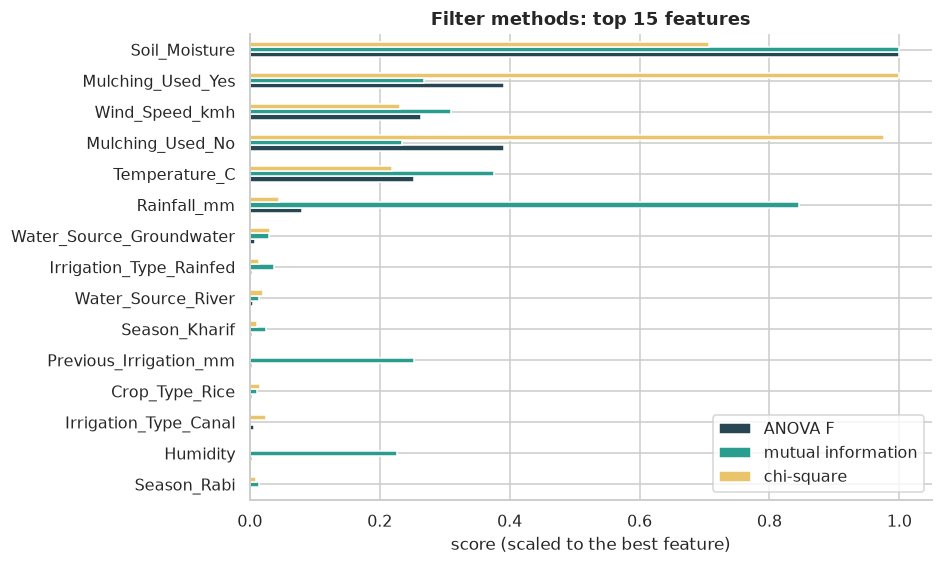

,ANOVA F,mutual information,chi-square
Soil_Moisture,3980.289,0.200,1008.159
Mulching_Used_Yes,1555.930,0.054,1426.792
Wind_Speed_kmh,1050.216,0.062,330.089
Mulching_Used_No,1555.930,0.047,1392.861
Temperature_C,1005.718,0.075,313.280
Rainfall_mm,320.261,0.170,64.522
Water_Source_Groundwater,28.960,0.006,43.484
Irrigation_Type_Rainfed,13.746,0.008,20.644
Water_Source_River,19.691,0.003,29.331
Season_Kharif,12.754,0.005,16.737


In [2]:
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.preprocessing import MinMaxScaler

f_scores, _ = f_classif(X, y)
mi = mutual_info_classif(X, y, random_state=0)
chi_scores, _ = chi2(MinMaxScaler().fit_transform(X), y)
filt = pd.DataFrame({"ANOVA F": f_scores, "mutual information": mi, "chi-square": chi_scores}, index=X.columns)
filt_rank = filt.rank(ascending=False).mean(axis=1).sort_values()
ax = (filt / filt.max()).loc[filt_rank.index[:15]].iloc[::-1].plot.barh(figsize=(8, 5.5), color=["#264653", "#2a9d8f", "#e9c46a"])
ax.set(xlabel="score (scaled to the best feature)", title="Filter methods: top 15 features")
plotting.save("i02-filter")
plt.show()
filt.loc[filt_rank.index[:10]].round(3)

The three filters agree on the leaders: soil moisture, mulching, wind speed, temperature and rainfall, and that most of the 40 encoded columns carry almost nothing. They miss one important feature, **growth stage**: its code runs Sowing 0 → Harvest 3, but only the *middle* two stages need water, so its effect isn't monotonic in the code and a one-feature-at-a-time score like ANOVA F underrates it. That is a blind spot of filter methods; the model-based scores below catch it.

### B. Wrapper methods
Search over feature *subsets* by actually training a model on each. Recursive feature elimination (RFE) starts with everything and repeatedly drops the weakest feature; forward sequential selection starts with nothing and adds the feature that helps most.

In [3]:
from sklearn.feature_selection import RFE, SequentialFeatureSelector

lr = LogisticRegression(max_iter=2000)
Xs = StandardScaler().fit_transform(X)
rfe = RFE(lr, n_features_to_select=8).fit(Xs, y)
sub = data.sample(6000, seed=2)
Xsub = StandardScaler().fit_transform(cols.transform(sub))
sfs = SequentialFeatureSelector(lr, n_features_to_select=8, direction="forward", scoring="balanced_accuracy", cv=3).fit(Xsub, sub[data.TARGET].cat.codes)
pd.DataFrame({"RFE keeps": X.columns[rfe.support_].tolist(), "forward selection keeps": X.columns[sfs.get_support()].tolist()})

,RFE keeps,forward selection keeps
0,Soil_Moisture,Soil_pH
1,Temperature_C,Soil_Moisture
2,Rainfall_mm,Temperature_C
3,Wind_Speed_kmh,Rainfall_mm
4,Crop_Type_Rice,Wind_Speed_kmh
5,Water_Source_Groundwater,Crop_Type_Rice
6,Mulching_Used_No,Mulching_Used_No
7,Mulching_Used_Yes,Region_West


### C. Embedded methods
Selection happens *inside* training: an L1 penalty drives useless weights to exactly zero, and a tree ensemble ranks features by how much they reduce impurity. Permutation importance, which shuffles one feature and measures how much the score drops, is the model-agnostic check.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

l1 = LogisticRegression(penalty="l1", solver="saga", C=0.02, max_iter=4000).fit(Xs, y)
kept_l1 = X.columns[np.abs(l1.coef_).max(axis=0) > 1e-6]
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(X, y)
perm = permutation_importance(rf, X.iloc[:5000], y[:5000], scoring="balanced_accuracy", n_repeats=5, random_state=0, n_jobs=-1)
emb = pd.DataFrame({"random forest impurity": rf.feature_importances_, "permutation (balanced acc. drop)": perm.importances_mean}, index=X.columns)
print(f"L1 (C = 0.02) keeps {len(kept_l1)} of {X.shape[1]} features:", ", ".join(kept_l1))
emb.sort_values("permutation (balanced acc. drop)", ascending=False).head(10).round(4)

/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


L1 (C = 0.02) keeps 33 of 40 features: Soil_pH, Soil_Moisture, Organic_Carbon, Electrical_Conductivity, Temperature_C, Humidity, Rainfall_mm, Sunlight_Hours, Wind_Speed_kmh, Field_Area_hectare, Previous_Irrigation_mm, Soil_Type_Loamy, Soil_Type_Silt, Crop_Type_Cotton, Crop_Type_Maize, Crop_Type_Potato, Crop_Type_Rice, Crop_Type_Wheat, Season_Kharif, Season_Rabi, Irrigation_Type_Canal, Irrigation_Type_Drip, Irrigation_Type_Rainfed, Irrigation_Type_Sprinkler, Water_Source_Groundwater, Water_Source_Rainwater, Water_Source_Reservoir, Water_Source_River, Mulching_Used_No, Mulching_Used_Yes, Region_Central, Region_West, Crop_Growth_Stage


,random forest impurity,permutation (balanced acc. drop)
Soil_Moisture,0.2747,0.3559
Crop_Growth_Stage,0.2520,0.2843
Temperature_C,0.1025,0.2389
Wind_Speed_kmh,0.1106,0.1976
Mulching_Used_Yes,0.0497,0.1172
Mulching_Used_No,0.0508,0.1155
Rainfall_mm,0.0347,0.0492
Electrical_Conductivity,0.0118,0.0062
Soil_pH,0.0118,0.0036
Organic_Carbon,0.0115,0.0034


How many features are actually needed? Keeping the top *k* by mutual information and cross-validating a random forest:

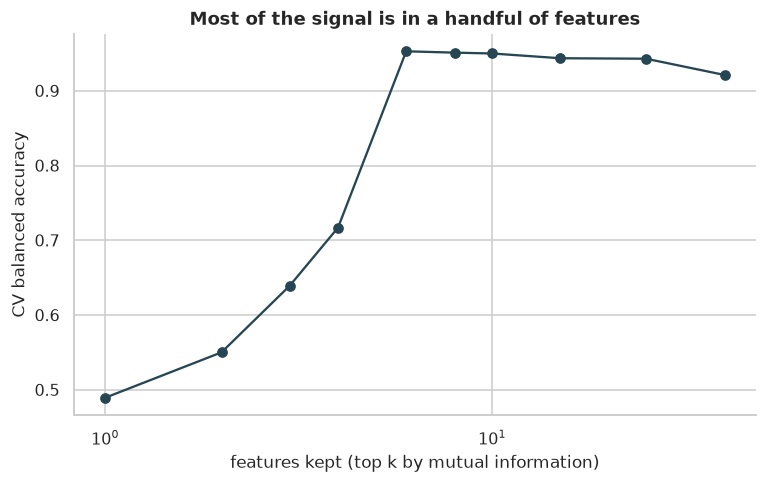

,1,2,3,4,6,8,10,15,25,40
balanced accuracy,0.4893,0.5501,0.6392,0.717,0.9528,0.951,0.9499,0.9435,0.9429,0.921


In [5]:
from sklearn.feature_selection import SelectKBest

ks = [1, 2, 3, 4, 6, 8, 10, 15, 25, 40]
curve = []
for k in ks:
    pipe = Pipeline([("columns", preprocess.column_transformer()), ("select", SelectKBest(lambda X_, y_: mutual_info_classif(X_, y_, random_state=0), k=k)),
                     ("model", RandomForestClassifier(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=0))])
    curve.append(cross_val_score(pipe, df, y, cv=3, scoring="balanced_accuracy").mean())
fig, ax = plt.subplots()
ax.plot(ks, curve, "o-", color=plotting.ACCENT)
ax.set(xscale="log", xlabel="features kept (top k by mutual information)", ylabel="CV balanced accuracy", title="Most of the signal is in a handful of features")
plotting.save("i02-k-features")
plt.show()
pd.Series(curve, index=ks, name="balanced accuracy").round(4).to_frame().T

Six features already give the best score (about 0.95). Keeping all 40 is *worse* (about 0.92): the forest spends some of its splits on columns that carry nothing. Selection isn't only about speed.

## 2. Feature extraction and engineering

### A. Feature extraction
Turning raw inputs into useful numbers: here, the one-hot and ordinal encodings from notebook 01; for unstructured data it would be image or text embeddings. PCA and LDA in section 4 are extraction too, building new features as combinations of the old ones.

### B. Creating new features
The EDA in CSE273 found that need depends on *combinations*: hot **and** dry, thirsty stage **and** no mulch, dry decile only. A linear model can't build those itself. `irrigate.features.DomainFeatures` adds them, each with an agronomic reason:

| Feature | Formula | Why |
|---|---|---|
| dryness | temperature / soil moisture | heat matters more when there is little water |
| evaporation_drive | temperature × wind speed | wind and heat together pull water out |
| water_supply | rainfall/1000 + previous irrigation/100 | water already delivered |
| thirsty_stage | stage ∈ {Vegetative, Flowering} | the only stages where High occurs |
| no_mulch, exposed_thirsty | no mulch, and thirsty stage × no mulch | the strongest interaction in the EDA |
| low_rain | rainfall below the training 10th percentile | the threshold effect found in the EDA |

In [6]:
engineered = DomainFeatures().fit(df).transform(df)
engineered[preprocess.ENGINEERED + [data.TARGET]].groupby(data.TARGET, observed=True).mean().T.round(3)

Irrigation_Need,Low,Medium,High
dryness,0.670,1.308,2.244
evaporation_drive,233.062,330.805,510.737
water_supply,2.111,2.083,1.628
thirsty_stage,0.267,0.817,0.967
no_mulch,0.382,0.664,0.890
exposed_thirsty,0.071,0.520,0.859
low_rain,0.079,0.103,0.424


In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

rows = []
for name, model in [("logistic regression", LogisticRegression(max_iter=3000)), ("gradient boosting", HistGradientBoostingClassifier(random_state=0))]:
    for label, pipe in [("raw features", preprocess.pipeline(model)), ("+ domain features", preprocess.pipeline(model, engineered=True)),
                        ("+ domain + aggregation", preprocess.group_pipeline(model))]:
        rows.append({"model": name, "features": label, "CV balanced accuracy": cross_val_score(pipe, df, y, cv=CV, scoring="balanced_accuracy").mean()})
fe = pd.DataFrame(rows).pivot(index="features", columns="model", values="CV balanced accuracy").loc[["raw features", "+ domain features", "+ domain + aggregation"]]
fe.round(4)

model,gradient boosting,logistic regression
features,,
raw features,0.9511,0.6268
+ domain features,0.9529,0.8054
+ domain + aggregation,0.9561,0.8055


The engineered features lift the linear model a lot: it now gets the interactions it couldn't build itself. Gradient boosting already finds interactions with its splits, so it gains less. That is the general rule: **feature engineering matters most for simple models.**

### C. Aggregation features
`GroupStats` compares each field with the average field of its group, for example "soil moisture relative to the average field of the same crop". The group means are learned in `fit()`, on the training fold only, so they are leak-free inside cross-validation. In this dataset the groups barely differ (crop and region don't change moisture or temperature), so the aggregation columns add little, as the last row above shows. They would matter for data where groups really differ, such as sales per store.

In [8]:
GroupStats().fit(df).transform(df.head(5))[["Crop_Type", "Soil_Moisture", "Soil_Moisture_vs_Crop_Type", "Region", "Temperature_C", "Temperature_C_vs_Region"]].round(2)

,Crop_Type,Soil_Moisture,Soil_Moisture_vs_Crop_Type,Region,Temperature_C,Temperature_C_vs_Region
0,Sugarcane,46.25,8.74,East,21.92,-5.00
1,Sugarcane,38.82,1.31,East,24.43,-2.49
2,Rice,12.41,-25.10,Central,34.78,7.91
3,Wheat,25.34,-12.34,West,21.88,-5.10
4,Rice,11.83,-25.68,South,35.37,8.42


## 3. Dimensionality reduction concepts

### A. The curse of dimensionality
In high dimensions, points spread out and every point becomes almost equally far from every other, so "nearest neighbour" loses its meaning. With random uniform points:

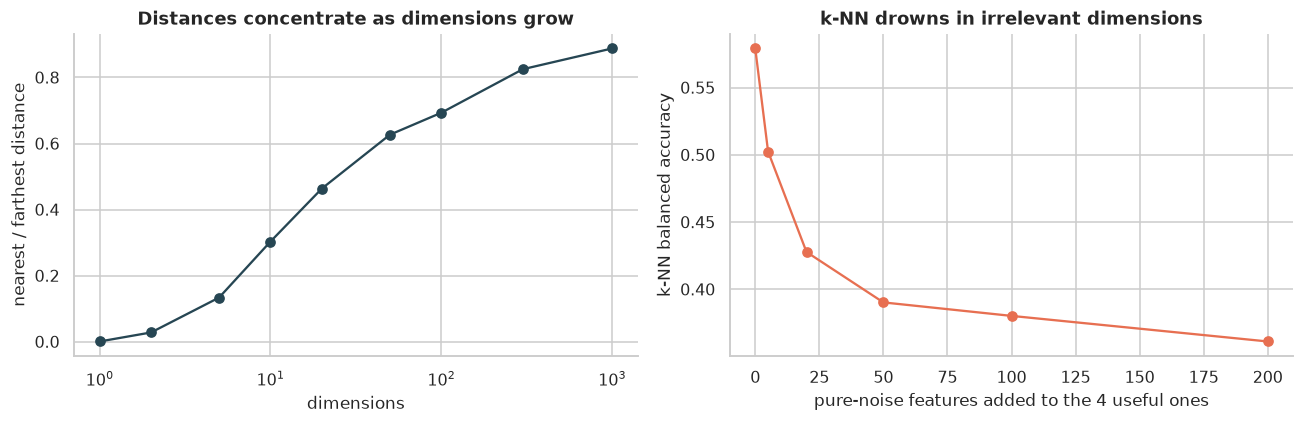

In [9]:
rng = np.random.default_rng(0)
dims = [1, 2, 5, 10, 20, 50, 100, 300, 1000]
ratio = []
for d in dims:
    P = rng.uniform(size=(500, d))
    dist = np.linalg.norm(P[1:] - P[0], axis=1)
    ratio.append(dist.min() / dist.max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dims, ratio, "o-", color=plotting.ACCENT)
axes[0].set(xscale="log", xlabel="dimensions", ylabel="nearest / farthest distance", title="Distances concentrate as dimensions grow")

# the same effect on real data: k-NN with pure-noise columns added
from sklearn.neighbors import KNeighborsClassifier
base = df.sample(8000, random_state=0)
yb = base[data.TARGET].cat.codes.to_numpy()
Xb = StandardScaler().fit_transform(base[["Soil_Moisture", "Temperature_C", "Wind_Speed_kmh", "Rainfall_mm"]])
noise_dims = [0, 5, 20, 50, 100, 200]
knn_scores = [cross_val_score(KNeighborsClassifier(15), np.hstack([Xb, rng.normal(size=(len(Xb), k))]), yb, cv=3, scoring="balanced_accuracy").mean() for k in noise_dims]
axes[1].plot(noise_dims, knn_scores, "o-", color="#e76f51")
axes[1].set(xlabel="pure-noise features added to the 4 useful ones", ylabel="k-NN balanced accuracy", title="k-NN drowns in irrelevant dimensions")
fig.tight_layout()
plotting.save("i02-curse")
plt.show()

### B. Dimensionality reduction
Two routes: **selection** keeps a subset of the original features (section 1); **extraction / projection** builds fewer new features from all of them (PCA, LDA).

## 4. Linear projection methods

### A. Principal component analysis (PCA)
Unsupervised: find orthogonal directions of maximum variance (the eigenvectors of the covariance matrix) and keep the first few.

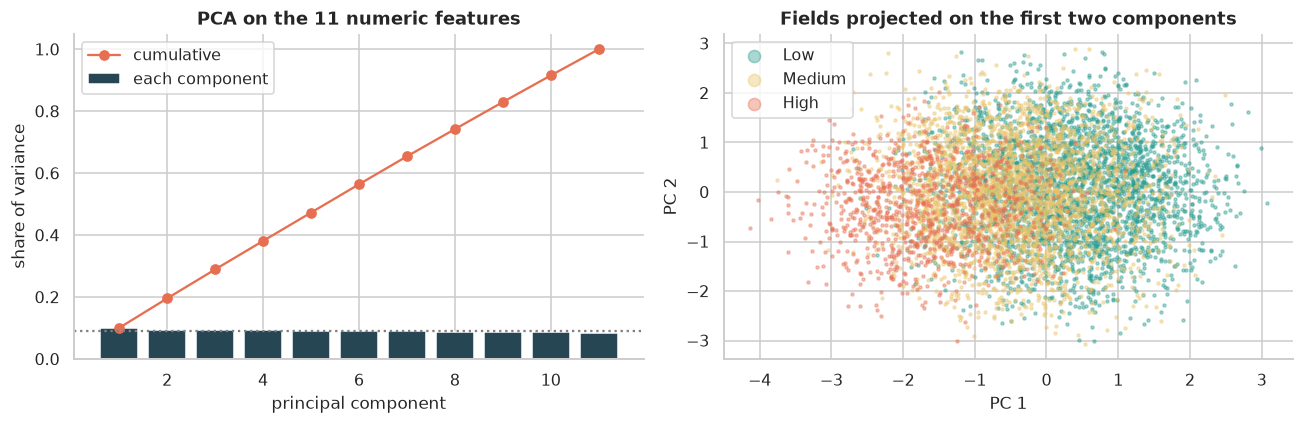

variance explained by each component: [0.1   0.095 0.093 0.092 0.092 0.091 0.09  0.088 0.087 0.086 0.085]


In [10]:
from sklearn.decomposition import PCA

num_scaled = StandardScaler().fit_transform(df[data.NUMERIC])
pca = PCA().fit(num_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 12), pca.explained_variance_ratio_, color=plotting.ACCENT, label="each component")
axes[0].plot(range(1, 12), np.cumsum(pca.explained_variance_ratio_), "o-", color="#e76f51", label="cumulative")
axes[0].axhline(1 / 11, ls=":", color="grey")
axes[0].set(xlabel="principal component", ylabel="share of variance", title="PCA on the 11 numeric features")
axes[0].legend()
Z = pca.transform(num_scaled)[:, :2]
for k, cls in enumerate(data.CLASSES):
    axes[1].scatter(Z[y == k, 0][:3000], Z[y == k, 1][:3000], s=4, alpha=0.4, color=plotting.CLASS_COLORS[cls], label=cls)
axes[1].set(xlabel="PC 1", ylabel="PC 2", title="Fields projected on the first two components")
axes[1].legend(markerscale=4)
fig.tight_layout()
plotting.save("i02-pca")
plt.show()
print("variance explained by each component:", np.round(pca.explained_variance_ratio_, 3))

Every component explains about 1/11 of the variance (the dotted line): the features are independent, as CSE273's correlation and eigenvalue analysis found, so PCA has nothing to compress. Its first components are not the directions that separate the classes either, because PCA never looks at the labels.

### B. Linear discriminant analysis (LDA)
Supervised: find directions that maximise the distance between class means relative to the spread within each class. With 3 classes there are at most 3 − 1 = 2 discriminant directions.

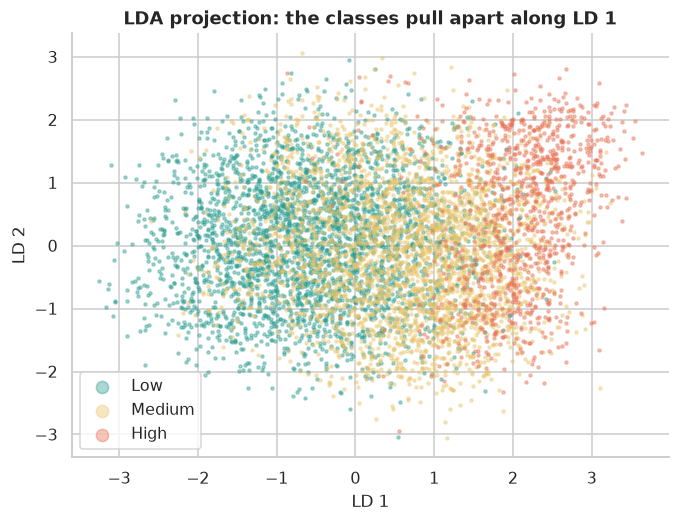

,weight in LD 1
Soil_Moisture,-0.929
Wind_Speed_kmh,0.511
Temperature_C,0.495
Rainfall_mm,-0.163
Humidity,-0.040
Previous_Irrigation_mm,0.027


In [11]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2).fit(num_scaled, y)
L = lda.transform(num_scaled)
fig, ax = plt.subplots(figsize=(7, 5))
for k, cls in enumerate(data.CLASSES):
    ax.scatter(L[y == k, 0][:3000], L[y == k, 1][:3000], s=4, alpha=0.4, color=plotting.CLASS_COLORS[cls], label=cls)
ax.set(xlabel="LD 1", ylabel="LD 2", title="LDA projection: the classes pull apart along LD 1")
ax.legend(markerscale=4)
plotting.save("i02-lda")
plt.show()
pd.Series(lda.scalings_[:, 0], index=data.NUMERIC).sort_values(key=abs, ascending=False).round(3).to_frame("weight in LD 1").head(6)

LD 1 is mostly −moisture, +wind and +temperature: LDA found the same "dryness" direction the EDA and the hand-made score in CSE273 found, this time automatically.

### Comparison: PCA vs LDA
The same 2-dimensional budget, used to classify:

In [12]:
rows = []
for name, reducer in [("all 11 numeric features", "passthrough"), ("PCA, 2 components", PCA(2)), ("LDA, 2 components", LinearDiscriminantAnalysis(n_components=2))]:
    pipe = make_pipeline(StandardScaler(), reducer, KNeighborsClassifier(25))
    rows.append({"input to k-NN": name, "CV balanced accuracy": cross_val_score(pipe, df[data.NUMERIC], y, cv=CV, scoring="balanced_accuracy").mean()})
pd.DataFrame(rows).round(4)

,input to k-NN,CV balanced accuracy
0,all 11 numeric features,0.5085
1,"PCA, 2 components",0.4833
2,"LDA, 2 components",0.5597


| | PCA | LDA |
|---|---|---|
| Uses the labels | no (unsupervised) | yes (supervised) |
| Finds directions of | maximum variance | maximum class separation |
| Number of components | up to the number of features | at most classes − 1 |
| Here | can't compress (independent features) and ignores the classes | 2 components beat all 11 raw features for k-NN |

| Syllabus topic | Where |
|---|---|
| Filter, wrapper and embedded feature selection | 1 A–C |
| Feature extraction, creating new features, aggregation features | 2 A–C |
| Curse of dimensionality, dimensionality reduction | 3 |
| PCA, LDA, comparison | 4 |